# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

My household is defined as a fresh graduate in boston, who works full time as an accounting associate at Deloitte.. They get to work via an old car, and their spending is mostly on rent, food, and a streaming subscription. They live in a 2 bedroom with a roommate.


> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [61]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    # {"Item": ..., "Price_2019": ..., "Price_2024": ..., "weight": ...}
    {"Item": "rent", "Price_2019":1100, "Price_2024": 1450, "weight":0.61 },
    {"Item": "Groceries", "Price_2019" :360, "Price_2024": 450, "weight":0.20 },
    {"Item": "Auto Insurance", "Price_2019": 100, "Price_2024": 120, "weight":0.06 },
    {"Item": "Spotify+Netflix subscription", "Price_2019":23, "Price_2024": 27.50, "weight":0.01 },
    {"Item": "Gas", "Price_2019":100, "Price_2024": 125, "weight":0.06 },
    {"Item": "Cell Plan/Internet", "Price_2019":100, "Price_2024": 120,"weight":0.06},
]

In [62]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [63]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    # YOUR CODE HERE
    total = 0
    for row in basket:
      price_ratio = row[current_key] / row[base_key]
      total = total + row["weight"] * price_ratio
    return total * 100


In [64]:
def price_change(old, new):
    """Percentage change from old to new."""
    return (new - old) / old * 100

price_change(2.00, 2.50)     # 25.0
# Using written example function for price change

# 1. the unweighted average price change across categories
unweighted_change = 0
for row in household_basket:
    change = price_change(row["Price_2019"], row["Price_2024"])
    print( row["Item"], round(change,1), "%")
    unweighted_change = unweighted_change + change

average_change = unweighted_change/ len(household_basket)
print("The Unweighted average change is:", round(average_change, 1), "%")

# 2. your weighted Laspeyres index
index_2024 = laspeyres(household_basket, "Price_2019" , "Price_2024")
print("Laspeyres index, with 2019 serving as 100:", round(index_2024, 1))

# 3. the gap between them
difference = (index_2024 - 100) - average_change
print("The difference is:", round(difference,1), "%")

rent 31.8 %
Groceries 25.0 %
Auto Insurance 20.0 %
Spotify+Netflix subscription 19.6 %
Gas 25.0 %
Cell Plan/Internet 20.0 %
The Unweighted average change is: 23.6 %
Laspeyres index, with 2019 serving as 100: 128.5
The difference is: 4.9 %


**Why do the two differ, and which would you defend to the client?**

* They have a large difference because the unweighted average does not account for the amount of the budget each category takes. The unweighted average does not factor in that the greater increase in rent is a much bigger factor than the lackluster increase in Spotify subscriptions. The Laspeyres index accounts for the fact that the rent is 61% of the households spending, and adjusts its index accordingly.

I would defedn the Laspeyres index, as it takes into the account the weight of the category in price differences, providing a more accurate estimation of how much more it costs to buy things.*

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [65]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "CUSR0000SETB01", "CUSR0000SERA02"]

def load_fred(series_id, start="1947-01-01", end=None):
    """Return one FRED series as a pandas Series indexed by date.

    Uses FRED's public CSV endpoint, which requires no API key. The CSV's
    second column is named after the series, and FRED has renamed that header
    before now, so we set the column names positionally rather than trusting
    them. Missing observations arrive as "." and become NaN.

    With no `end`, you get everything FRED has published so far. A fixed end
    date goes stale: the Big Mac data in Part 4 runs past it, and a 2026 price
    deflated with a 2025 CPI is in the wrong year's dollars.
    """
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()
cpi = load_fred("CPIAUCSL", start = "1900-01-01")
rent = load_fred("CUSR0000SEHA", start =  "1900-01-01")
groceries = load_fred("CUSR0000SAF11", start =  "1900-01-01")
used_cars = load_fred("CUSR0000SETA02", start =  "1900-01-01")
gas = load_fred("CUSR0000SETB01", start = "1900-01-01")
streaming = load_fred("CUSR0000SERA02", start = "1900-01-01")

print("CPI:    ", cpi.index.min().date(), "to", cpi.index.max().date())
print("CPI:    ", rent.index.min().date(), "to", rent.index.max().date())
print("CPI:    ", groceries.index.min().date(), "to", groceries.index.max().date())
print("CPI:    ", used_cars.index.min().date(), "to", used_cars.index.max().date())
print("CPI:    ", gas.index.min().date(), "to", gas.index.max().date())
print("CPI:    ", streaming.index.min().date(), "to", streaming.index.max().date())

CPI:     1947-01-01 to 2026-08-01
CPI:     1981-01-01 to 2026-08-01
CPI:     1952-01-01 to 2026-08-01
CPI:     1953-01-01 to 2026-08-01
CPI:     1967-01-01 to 2026-08-01
CPI:     1992-01-01 to 2026-08-01


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | It is a good benchmark for all consumer pricing buckets, it is the most common inflation metric. | Doesn't accurately represent the construction of my household, which is extremely rent dominated |
| `CUSR0000SEHA` | It tracks rent, which is most households largest expense. It tracks for urban locations, which fits my profile.| Although it is urban, it is still a National measure and not Boston. It is also reliant on existing data, meaning it does not account for increased cost of new leases that is representative of my household. |
| `CUSR0000SAF11` | The bucket that tracks down cost of eating food at home, which can serve as a measure for groceries. This works well for my household. | This is also a national average, and is not boston specific, could miss certain taxes or fees only levied in MA. |
| `CUSR0000SETA02` | This household is reliant on a used car for transportation, so this data index is fitting. | This measures the price of buying a used car, this household has already done that. It does not work for this situation. |
| `CUSR0000SETB01` | Tracks gas prices, which the car is reliant on. |This again is a national average, MA prices would be more accurate.|
| `CUSR0000SERA02` | This is imperfect, but covers most of the households subscriptions. It tracks the price of how streaming services have changed. | It only covers TV subscriptions, so it still leaves out cell phone plans, and internet.|






### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [66]:
# Rebase to 2019 = 100
def rebase(series, base_year = 2019):
  base = series.loc[series.index.year == base_year].mean()
  return series / base * 100

cpi_rebased = rebase(cpi)
rent_rebased = rebase(rent)
groceries_rebased = rebase(groceries)
used_cars_rebased = rebase(used_cars)
gas_rebased = rebase(gas)
streaming_rebased = rebase(streaming)

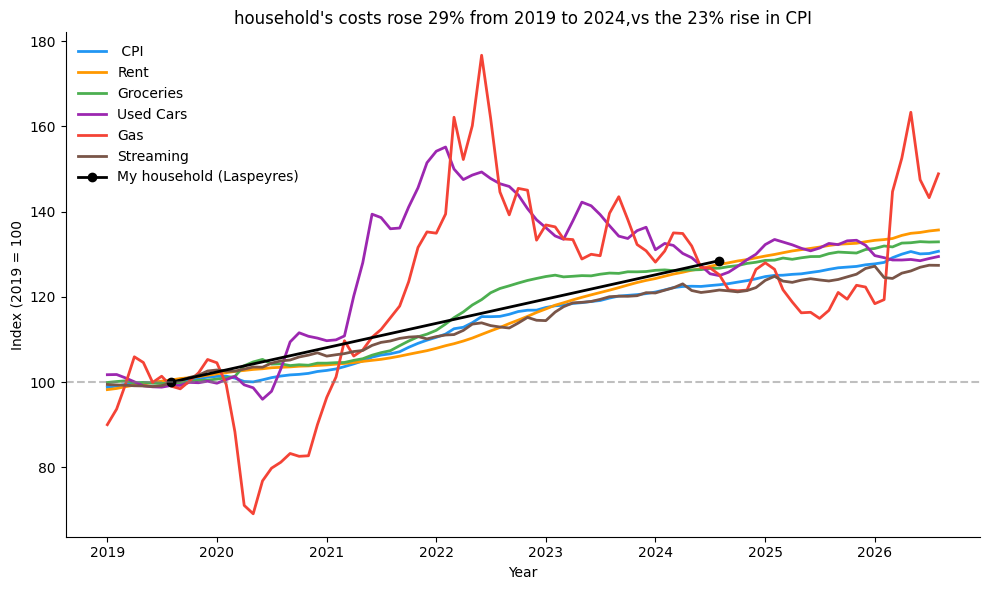

In [67]:
# One chart: every rebased series, plus your household index

cpi_plot = cpi_rebased.loc[cpi_rebased.index.year >= 2019]
rent_plot = rent_rebased.loc[rent_rebased.index.year >= 2019]
groceries_plot = groceries_rebased.loc[groceries_rebased.index.year >= 2019]
used_cars_plot = used_cars_rebased.loc[used_cars_rebased.index.year >= 2019]
gas_plot = gas_rebased.loc[gas_rebased.index.year >= 2019]
streaming_plot = streaming_rebased.loc[streaming_rebased.index.year >= 2019]

cpi_change = cpi_rebased.loc[cpi_rebased.index.year == 2024].mean() - 100

# for all rebased series

fig, ax = plt.subplots(figsize = (10,6))
ax.plot(cpi_plot.index, cpi_plot, label = " CPI", color = "#2196F3", linewidth = 2)
ax.plot(rent_plot.index, rent_plot, label = "Rent", color = "#FF9800", linewidth = 2)
ax.plot(groceries_plot.index, groceries_plot, label = "Groceries", color = "#4CAF50", linewidth = 2)
ax.plot(used_cars_plot.index, used_cars_plot, label = "Used Cars", color = "#9C27B0", linewidth = 2)
ax.plot(gas_plot.index, gas_plot, label = "Gas", color = "#F44336", linewidth = 2)
ax.plot(streaming_plot.index, streaming_plot, label = "Streaming", color = "#795548", linewidth = 2)

#household
ax.plot(pd.to_datetime(["2019-08-01", "2024-08-01"]), [100, index_2024],
        label = "My household (Laspeyres)", color = "#000000", linewidth=2, marker ="o")
ax.axhline(y = 100, color = "gray", linestyle = "--", alpha = 0.5)
ax.set_xlabel("Year")
ax.set_ylabel("Index (2019 = 100")
ax.set_title(f"household's costs rose {index_2024 - 100:.0f}% from 2019 to 2024,"
             f"vs the {cpi_change:.0f}% rise in CPI")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()






---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [68]:
# First observation, last observation, frequency and missing months, for every series

def audit(name, s):
  grid = s.asfreq("MS")
  print(name)
  print(" First:", s.index.min().date())
  print(" Last:", s.index.max().date())
  print( "Observations in 2019:", len(s.loc[s.index.year == 2019]))
  print( "Missing months:", grid.isna().sum())
  print(grid[grid.isna()])
  print()


audit("CPIAUCSL", cpi)
audit("CUSR0000SEHA", rent)
audit("CUSR0000SAF11", groceries)
audit("CUSR0000SETA02", used_cars)
audit("CUSR0000SETB01", gas)
audit("CUSR0000SERA02", streaming)



CPIAUCSL
 First: 1947-01-01
 Last: 2026-08-01
Observations in 2019: 12
Missing months: 1
date
2025-10-01   NaN
Freq: MS, Name: CPIAUCSL, dtype: float64

CUSR0000SEHA
 First: 1981-01-01
 Last: 2026-08-01
Observations in 2019: 12
Missing months: 1
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SEHA, dtype: float64

CUSR0000SAF11
 First: 1952-01-01
 Last: 2026-08-01
Observations in 2019: 12
Missing months: 1
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SAF11, dtype: float64

CUSR0000SETA02
 First: 1953-01-01
 Last: 2026-08-01
Observations in 2019: 12
Missing months: 0
Series([], Freq: MS, Name: CUSR0000SETA02, dtype: float64)

CUSR0000SETB01
 First: 1967-01-01
 Last: 2026-08-01
Observations in 2019: 12
Missing months: 0
Series([], Freq: MS, Name: CUSR0000SETB01, dtype: float64)

CUSR0000SERA02
 First: 1992-01-01
 Last: 2026-08-01
Observations in 2019: 12
Missing months: 1
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SERA02, dtype: float64



| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| | | | | |

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [69]:
# Start dates side by side, and the common sample
print("CPIAUCSL starts:      ", cpi.index.min().date())
print("CUSR0000SEHA starts:      ", rent.index.min().date())
print("CUSR0000SAF11 starts:      ", groceries.index.min().date())
print("CUSR0000SETA02 starts:      ", used_cars.index.min().date())
print("CUSR0000SETB01 starts:      ", gas.index.min().date())
print("CUSR0000SERA02 starts:      ", streaming.index.min().date())

all_data = pd.DataFrame({"CPIAUCSL": cpi,"CUSR0000SEHA": rent, "CUSR0000SAF11": groceries,
                         "CUSR0000SETA02": used_cars, "CUSR0000SETB01": gas,
                         "CUSR0000SERA02": streaming})
common = all_data.dropna()

common_start = common.index.min()
discarded = len(cpi.loc[cpi.index < common_start])

print("\nCommon sample starts:", common_start.date())
print("Common sample length:", len(common), "months")
print("Months of CPIAUCSL (the longest series) discarded:", discarded)




CPIAUCSL starts:       1947-01-01
CUSR0000SEHA starts:       1981-01-01
CUSR0000SAF11 starts:       1952-01-01
CUSR0000SETA02 starts:       1953-01-01
CUSR0000SETB01 starts:       1967-01-01
CUSR0000SERA02 starts:       1992-01-01

Common sample starts: 1992-01-01
Common sample length: 415 months
Months of CPIAUCSL (the longest series) discarded: 540


In [70]:
# Headline comparison: full history vs common sample

def total_change(s):

  return ((s.iloc[-1] / s.iloc[0]) - 1) * 100

print(" Full history (all series from start):")
print( " CPI:    ", round(total_change(cpi), 1), "%")
print( " Rent:    ", round(total_change(rent), 1), "%")
print( " Groceries:    ", round(total_change(groceries), 1), "%")
print( " Used cars:    ", round(total_change(used_cars), 1), "%")
print( " Gas:    ", round(total_change(gas), 1), "%")
print( " Streaming:    ", round(total_change(streaming), 1), "%")

print("\n Common sample only (the overlap, not including missing months):")
print( " CPI:     ", round(total_change(common["CPIAUCSL"]), 1), "%")
print( " Rent:     ", round(total_change(common["CUSR0000SEHA"]), 1), "%")
print( " Groceries:     ", round(total_change(common["CUSR0000SAF11"]), 1), "%")
print( " Used cars:     ", round(total_change(common["CUSR0000SETA02"]), 1), "%")
print( " Gas:     ", round(total_change(common["CUSR0000SETB01"]), 1), "%")
print( " Streaming:     ", round(total_change(common["CUSR0000SERA02"]), 1), "%")





 Full history (all series from start):
 CPI:     1455.5 %
 Rent:     430.5 %
 Groceries:     929.9 %
 Used cars:     530.5 %
 Gas:     1212.4 %
 Streaming:     237.8 %

 Common sample only (the overlap, not including missing months):
 CPI:      141.6 %
 Rent:      209.0 %
 Groceries:      137.7 %
 Used cars:      52.6 %
 Gas:      255.8 %
 Streaming:      237.8 %


**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting to the common sample assumes that all of the data will be measured across the same months. It assumes that the only way to make a proper comparison is by eliminating data in which all of the thresholds did not exist.

Not Restricting assumes that that all of the changes across all of the different time spans can be compared against each other. This can be misleading though, as data that started in the 1920s or 1940s will have decades upon decades more inflation than the dataset that started in 1992.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

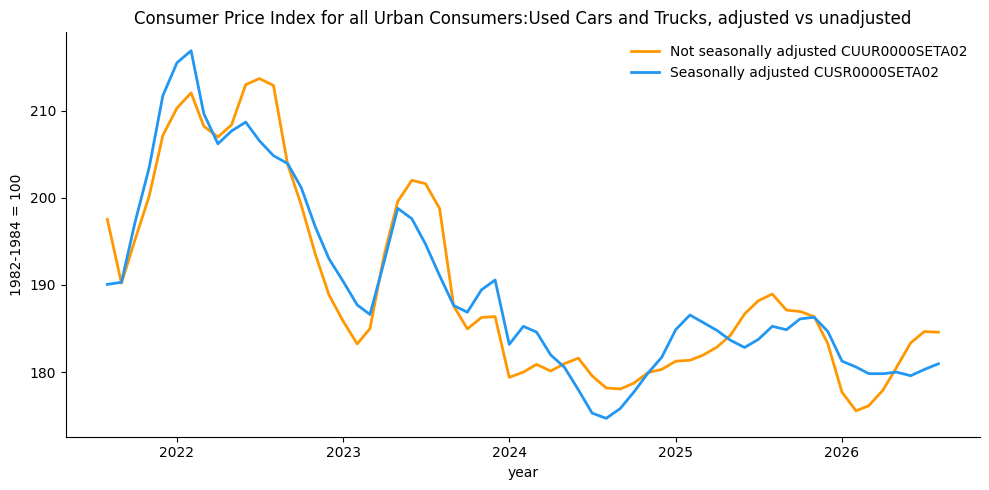

In [71]:
# Seasonally adjusted vs unadjusted, last five years

used_cars_nsa = load_fred("CUUR0000SETA02", start = "1900-01-01")

start = pd.to_datetime("2021-08-01")
sa_plot = used_cars.loc[used_cars.index >= start]
nsa_plot = used_cars_nsa.loc[used_cars_nsa.index >= start]

fig, ax = plt.subplots(figsize = (10,5))
ax.plot(nsa_plot.index, nsa_plot, label = "Not seasonally adjusted CUUR0000SETA02",
        color = "#FF9800", linewidth = 2)
ax.plot(sa_plot.index, sa_plot, label = "Seasonally adjusted CUSR0000SETA02",
        color = "#2196F3", linewidth = 2)
ax.set_xlabel("year")
ax.set_ylabel("1982-1984 = 100")
ax.set_title("Consumer Price Index for all Urban Consumers:Used Cars and Trucks, adjusted vs unadjusted")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()



**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines can be explained by the seasonal factor. The difference in charts each year usually peaks around the same point. In the summer, unadjusted prices run above the adjusted ones, and the opposite effect takes place in thw winter. The gap is just a facet of this adjustment, and the seasonal differences cacnel each other out, it is not from observed data.

I would include the adjusted series, as it is a comparison of how much more the household pays in 2024 vs 2019. The seasonal difference is canceled out over the year, and the comparison uses full year average so unadjusted is a better indicator overall. If it were for a specific month in 2019 and 2024, I would recommend using the adjustment.



---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Baseline Laspeyres Index: 128.50

Sensitivity ranking:
                              Index_Min  Index_Max  Sensitivity_Range
Item                                                                 
Cell Plan/Internet              124.524    129.048              4.524
Auto Insurance                  124.524    129.048              4.524
Spotify+Netflix subscription    124.080    128.595              4.515
rent                            123.322    127.570              4.248
Groceries                       127.190    129.381              2.190
Gas                             126.864    128.728              1.864

Most sensitive category: Cell Plan/Internet


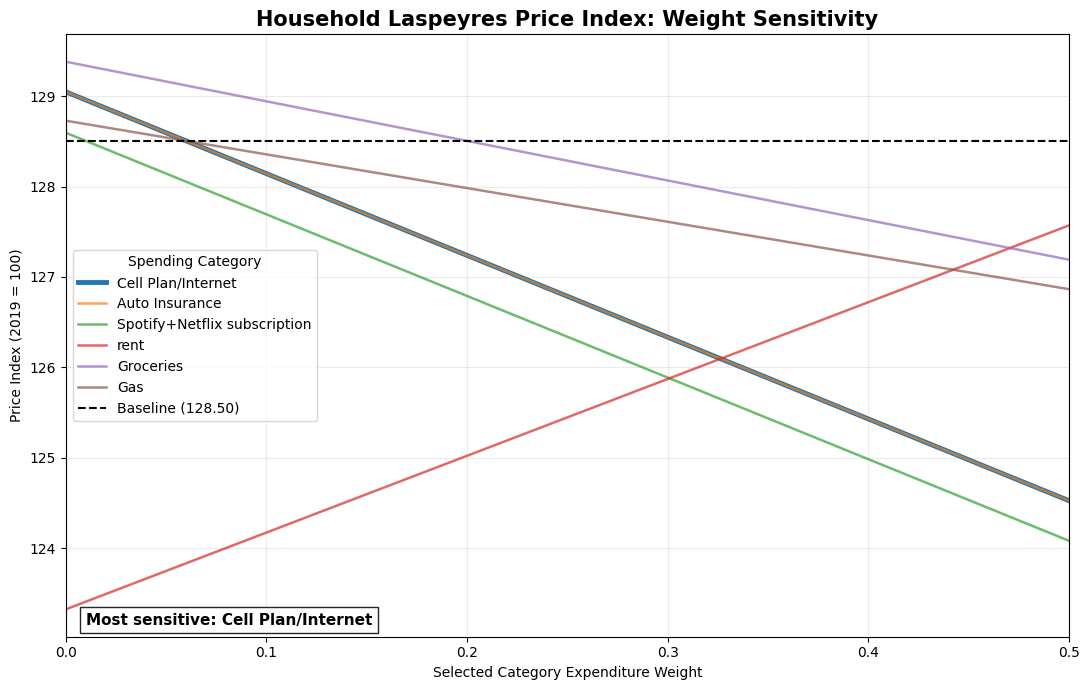

In [73]:
# Paste the AI's code here, run it, and correct it where it is wrong
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------
# 1. Prepare the household basket
# -------------------------------------------------------

df = pd.DataFrame(household_basket).copy()

required = {"Item", "Price_2019", "Price_2024", "weight"}
assert required.issubset(df.columns), "Missing required columns."
assert len(df) == 6, "Expected six spending categories."

for col in ["Price_2019", "Price_2024", "weight"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

assert df["Item"].is_unique, "Category names must be unique."
assert np.isfinite(df[["Price_2019", "Price_2024", "weight"]]).all().all()
assert (df["Price_2019"] > 0).all(), "Base prices must be positive."
assert (df["weight"] >= 0).all(), "Weights must be nonnegative."
assert df["weight"].sum() > 0, "Weights must have a positive sum."

# Normalize the original weights to sum to 1.
df["weight"] = df["weight"] / df["weight"].sum()

# Category-specific price relatives.
df["price_relative"] = df["Price_2024"] / df["Price_2019"]


# -------------------------------------------------------
# 2. Define the weighted Laspeyres index
# -------------------------------------------------------

def laspeyres_index(weights):
    """
    Weighted average of category price relatives,
    expressed as an index with 2019 = 100.

    Assumes 'weight' represents base-period expenditure
    shares, not physical quantities.
    """
    return 100 * np.dot(weights, df["price_relative"])


baseline_index = laspeyres_index(df["weight"].to_numpy())

print(f"Baseline Laspeyres Index: {baseline_index:.2f}")


# -------------------------------------------------------
# 3. Sweep each category's weight from 0 to 0.5
# -------------------------------------------------------

weight_grid = np.linspace(0, 0.5, 101)

results = []

for i, row in df.iterrows():

    original_weights = df["weight"].to_numpy()

    other_mask = np.ones(len(df), dtype=bool)
    other_mask[i] = False

    other_weights = original_weights[other_mask]
    other_total = other_weights.sum()

    if other_total == 0:
        raise ValueError(
            f"Cannot proportionally redistribute weights "
            f"when {row['Item']} has all the original weight."
        )

    for new_weight in weight_grid:

        adjusted_weights = original_weights.copy()

        # Fix the selected category at the proposed weight.
        adjusted_weights[i] = new_weight

        # Renormalize the other five weights proportionally.
        #
        # WHY THIS MATTERS:
        # Expenditure shares must always sum to 1.
        # Increasing one category's share necessarily reduces
        # the combined share of the remaining categories.
        #
        # Scaling proportionally preserves the relative
        # importance of the other five categories, isolating
        # the effect of changing the selected category.
        adjusted_weights[other_mask] = (
            other_weights / other_total
        ) * (1 - new_weight)

        assert np.isclose(adjusted_weights.sum(), 1)

        new_index = laspeyres_index(adjusted_weights)

        results.append({
            "Item": row["Item"],
            "weight": new_weight,
            "Index": new_index,
            "Change_from_baseline": new_index - baseline_index
        })

sensitivity_df = pd.DataFrame(results)


# -------------------------------------------------------
# 4. Quantify sensitivity for each category
# -------------------------------------------------------

summary = (
    sensitivity_df
    .groupby("Item")
    .agg(
        Index_Min=("Index", "min"),
        Index_Max=("Index", "max")
    )
)

summary["Sensitivity_Range"] = (
    summary["Index_Max"] - summary["Index_Min"]
)

summary = summary.sort_values(
    "Sensitivity_Range",
    ascending=False
)

dominant_category = summary.index[0]

print("\nSensitivity ranking:")
print(summary.round(3))

print(f"\nMost sensitive category: {dominant_category}")


# -------------------------------------------------------
# 5. Plot all six sensitivity curves in one chart
# -------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

for category in summary.index:

    subset = sensitivity_df[
        sensitivity_df["Item"] == category
    ]

    is_dominant = category == dominant_category

    ax.plot(
        subset["weight"],
        subset["Index"],
        label=category,
        linewidth=3.5 if is_dominant else 1.8,
        alpha=1.0 if is_dominant else 0.7
    )

# Baseline index for reference.
ax.axhline(
    baseline_index,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline ({baseline_index:.2f})"
)

ax.set_title(
    "Household Laspeyres Price Index: Weight Sensitivity",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Selected Category Expenditure Weight")
ax.set_ylabel("Price Index (2019 = 100)")

ax.set_xlim(0, 0.5)
ax.grid(True, alpha=0.25)
ax.legend(title="Spending Category")

ax.text(
    0.02,
    0.02,
    f"Most sensitive: {dominant_category}",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    bbox=dict(facecolor="white", alpha=0.85)
)

plt.tight_layout()
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

The model got a few things right. It's index matched the laspeyres index (128.50), that I was able to calculate in the early phase. The lines are graphed correctly, and it weighted the indexes.

It did get multiple things wrong though. Its sweep was capped out at 0.5, and since the rent is weighted at .61, the AIs rent curve was below the baseline. The chart is unable to produce my result with rent. The logic behind the most sensitive pick was also strange, there is a tie between two categories, and it did not provide reasoning as to why it chose Cell Plan over Auto Insurance.

### AI Transcript

**Model:OPEN_AI-GPT6 &nbsp; **10/10/2027:**
https://chatgpt.com/s/t_6acb062586f88191aa9a17e4569f994d.

[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.
Below is a reproducible sensitivity analysis using NumPy, pandas, and Matplotlib only. It reuses your household_basket variable and produces one chart comparing the sensitivity of your Laspeyres price index to each of the six spending categories.

The key question is: How much does the household price index change when we vary one category's expenditure weight from 0% to 50%, while preserving the relative weights of the remaining five categories?

1. Python code
summary["Sensitivity_Range"] = (
    summary["Index_Max"] - summary["Index_Min"]
)

summary = summary.sort_values(
    "Sensitivity_Range",
    ascending=False
)

dominant_category = summary.index[0]

print("\nSensitivity ranking:")
print(summary.round(3))

print(f"\nMost sensitive category: {dominant_category}")


# -------------------------------------------------------
# 5. Plot all six sensitivity curves in one chart
# -------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

for category in summary.index:

    subset = sensitivity_df[
        sensitivity_df["Item"] == category
    ]

    is_dominant = category == dominant_category

    ax.plot(
        subset["weight"],
        subset["Index"],
        label=category,
        linewidth=3.5 if is_dominant else 1.8,
        alpha=1.0 if is_dominant else 0.7
    )

# Baseline index for reference.
ax.axhline(
    baseline_index,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline ({baseline_index:.2f})"
)

ax.set_title(
    "Household Laspeyres Price Index: Weight Sensitivity",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Selected Category Expenditure Weight")
ax.set_ylabel("Price Index (2019 = 100)")


2. How to interpret the chart
Each line shows how the index responds when one spending category receives between 0% and 50% of total expenditure.

The other five categories retain their relative expenditure shares.

Chart feature	Economic interpretation
Steep upward slope	Increasing this category's weight raises measured inflation.
Steep downward slope	Increasing this category's weight lowers measured inflation.
Nearly horizontal line	The index is relatively insensitive to this category's weight.
Largest vertical range	The category has the greatest sensitivity over the tested interval.
Baseline horizontal line	The index calculated using the original expenditure weights.
The category with the largest vertical range is the most influential under this sensitivity experiment.

Why proportional renormalization matters
Suppose housing originally accounts for 30% of expenditure and food accounts for 20%.

If housing increases to 40%, the remaining categories must collectively fall from 70% to 60%.

Food's adjusted weight becomes:

w
food,new
=
0.20
×
0.60
0.70
=
0.1714
w
food,new
​
 =0.20×
0.70
0.60
​
 =0.1714
Thus, food falls from 20% to approximately 17.14%.

Without renormalization, the weights would no longer sum to 100%, making the index economically inconsistent.

3. What actually determines sensitivity?
Your index is:

L
=
100
∑
i
=
1
6
w
i
P
i
,
2024
P
i
,
2019
L=100
i=1
∑
6
​
 w
i
​
  
P
i,2019
​

P
i,2024
​

​

Define the category price relative:

R
i
=
P
i
,
2024
P
i
,
2019
R
i
​
 =
P
i,2019
​

P
i,2024
​

​

When category
i
i's weight changes to
w
w, the adjusted index is:

L
i
(
w
)
=
100
[
w
R
i
+
(
1
−
w
)
R
ˉ
−
i
]
L
i
​
 (w)=100[wR
i
​
 +(1−w)
R
ˉ
  
−i
​
 ]
​

where
R
ˉ
−
i
R
ˉ
  
−i
​
  is the weighted average price relative of the other five categories, using their original relative weights.

Differentiating:

d
L
i
d
w
=
100
(
R
i
−
R
ˉ
−
i
)
dw
dL
i
​

​
 =100(R
i
​
 −
R
ˉ
  
−i
​
 )
​

This gives an important economic insight:

Sensitivity is determined by how different a category's price increase is from the weighted average price increase of the other categories.

It is not necessarily determined by which category has the largest original expenditure weight.

For example, a category with a relatively small expenditure share can still generate substantial sensitivity if its price increase is exceptionally large.

Because your sweep covers a weight interval of 0.5, the total index range for category
i
i is:

S
i
=
50
∣
R
i
−
R
ˉ
−
i
∣
S
i
​
 =50∣R
i
​
 −
R
ˉ
  
−i
​
 ∣
​

This is measured in index points, not percentage points of inflation.

4. Which category dominates your result?
Your actual household_basket values weren't included in the message, so I cannot identify the winning category without inventing data.

The code identifies it automatically using:

dominant_category = summary.index[0]

It also prints all six categories ranked by sensitivity.

There is one important distinction when reporting the result:

Sensitivity: Which category produces the largest index movement when its weight changes?
Contribution: Which category contributes the most to the baseline index's increase since 2019?
These are different economic questions. A category can have the highest sensitivity without making the largest contribution to observed household inflation.

If you also want to identify the largest contributor, add:

df["Inflation_Contribution"] = (
    100 * df["weight"] * (df["price_relative"] - 1)
)

print(
    df[["Item", "Inflation_Contribution"]]
    .sort_values("Inflation_Contribution", ascending=False)
)

The contributions sum to the baseline index minus 100.

5. What to tell your client
The appropriate client-facing interpretation is:

Our sensitivity analysis examines how the household price index changes when each expenditure category's weight is varied between 0% and 50%, while the remaining expenditure weights are adjusted proportionally.

The analysis identifies the category whose relative price movement differs most substantially from the weighted average of the other categories. Consequently, assumptions about this category's expenditure share have the greatest effect on the estimated household price index.

A high degree of sensitivity does not necessarily indicate an error in the index. Rather, it highlights the importance of accurately estimating expenditure shares and evaluating whether the assumed household spending patterns are representative.

We recommend validating the expenditure weight assigned to the most sensitive category and reporting the baseline index alongside plausible alternative weighting scenarios.

One additional methodological recommendation
A 0–50% sweep is useful for stress testing, but some scenarios may be unrealistic for a typical household.

For a client deliverable, I would distinguish between:

1. Structural sensitivity: Your requested 0–50% sweep, which measures how strongly the index depends on each category.

2. Plausible uncertainty: A narrower range around each category's actual expenditure share, such as ±5 percentage points, subject to feasible bounds.

The second is often more useful for determining whether uncertainty in the expenditure weights could materially change the client's conclusion.

Bottom line: Your analysis will identify the category that makes the index most sensitive to expenditure-weight assumptions. That is not necessarily the category contributing the most to inflation. Both measures are useful, but they answer different questions.

If you paste your six household_basket dictionaries, I can identify the actual dominant category, quantify its effect on the index, and provide a specific client-ready conclusion.

what model is this?
You're chatting with OpenAI GPT-6.



### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

f all 12% of these spendings were inaccurate, the gap would still exist.

This households cost of living rose roughly 28.5% from 2019 to 2024, outgaining the rise in the overall CPI index. This means that their cost of living

This difference is driven by rent, as it is 61% of the households spending, and was also the largest riser of the categories. This is not represented in the CPI because most households do not spend this much money on their rent, compared to a new grad/college student, and the national rent uses existing leases, and not the market someone would face trying to find a lease.

This finding remains to be true, even in different scenarios. Any household with this high of a rent share will face a cost of living increase much higher. Even if rent was lower, the households costs still would have risen beyond the cpi.

I am very confident in this result, the prices used are published averages and tested information, and only 12% of the households spendings have no government information to back it up. Even i

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub